# Semana 2 — Matemáticas para modelos: Euler frente a la solución analítica

**Objetivo:** entender que una simulación es una *aproximación* de una ecuación diferencial y
medir cómo depende su error del paso temporal $\Delta t$.

## Modelo

Decaimiento exponencial (la parte pasiva de una membrana):

$$\frac{dV}{dt} = -\frac{V}{\tau}, \qquad V(0) = V_0 \quad\Longrightarrow\quad V(t) = V_0\, e^{-t/\tau}$$

El método de **Euler explícito** reemplaza la derivada por una diferencia finita:

$$V_{k+1} = V_k + \Delta t \left(-\frac{V_k}{\tau}\right) = V_k \left(1 - \frac{\Delta t}{\tau}\right)$$

Euler es un método de **primer orden**: el error global es proporcional a $\Delta t$.
En escala log–log, el error frente a $\Delta t$ debe ser una recta de pendiente ≈ 1.

Parámetros: $\tau = 5$ (unidades arbitrarias de tiempo), $V_0 = 1$, duración 20.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience.outputs import save_data, save_figure

WEEK = 2
TAU = 5.0
DURATION = 20.0
V0 = 1.0
STEPS = np.array([2.0, 1.0, 0.5, 0.25, 0.1, 0.05])


def euler_decay(step: float) -> tuple[np.ndarray, np.ndarray]:
    time = np.arange(0.0, DURATION + step / 2, step)
    values = np.empty(time.size)
    values[0] = V0
    for index in range(time.size - 1):
        values[index + 1] = values[index] - step * values[index] / TAU
    return time, values


max_errors = []
traces = {}
for step in STEPS:
    time, values = euler_decay(step)
    max_errors.append(np.max(np.abs(values - V0 * np.exp(-time / TAU))))
    traces[f"euler_dt_{step:g}"] = values
max_errors = np.array(max_errors)
order = np.polyfit(np.log(STEPS), np.log(max_errors), 1)[0]

## Figura

Izquierda: tres pasos de Euler frente a la solución exacta (línea negra discontinua, dibujada
encima). Derecha: error máximo frente a $\Delta t$ en escala log–log, con la pendiente ajustada.

Saved: weeks/week_02_math_and_euler/outputs/euler_convergence.png
Saved: weeks/week_02_math_and_euler/outputs/euler_convergence.npz


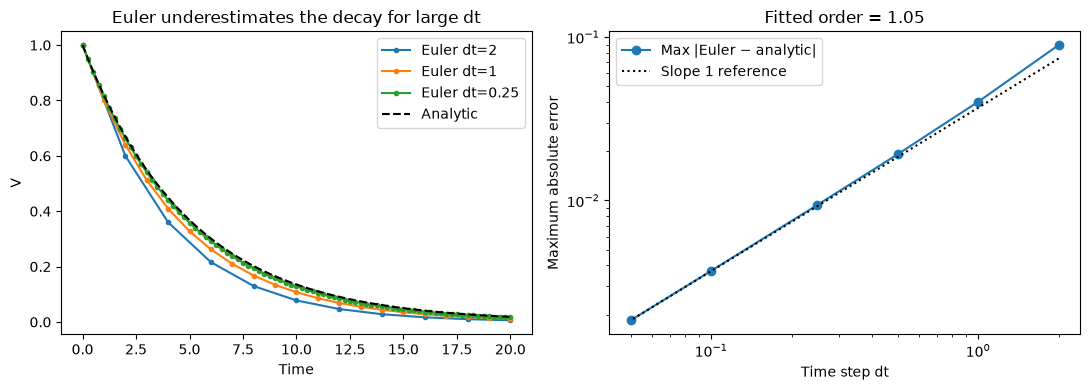

In [2]:
time_fine = np.linspace(0.0, DURATION, 1001)
analytic = V0 * np.exp(-time_fine / TAU)
figure, axes = plt.subplots(1, 2, figsize=(11, 4))
for step in (2.0, 1.0, 0.25):
    time, values = euler_decay(step)
    axes[0].plot(time, values, marker=".", label=f"Euler dt={step:g}")
axes[0].plot(time_fine, analytic, "k--", linewidth=1.5, label="Analytic", zorder=5)
axes[0].set(xlabel="Time", ylabel="V", title="Euler underestimates the decay for large dt")
axes[0].legend()

axes[1].loglog(STEPS, max_errors, "o-", label="Max |Euler − analytic|")
axes[1].loglog(STEPS, max_errors[-1] * STEPS / STEPS[-1], "k:", label="Slope 1 reference")
axes[1].set(xlabel="Time step dt", ylabel="Maximum absolute error", title=f"Fitted order = {order:.2f}")
axes[1].legend()
save_figure(WEEK, figure, "euler_convergence.png")
save_data(WEEK, "euler_convergence.npz", steps=STEPS, max_errors=max_errors, time_fine=time_fine, analytic=analytic, **traces)

## Validación

- El error debe disminuir de forma monótona al reducir $\Delta t$.
- La pendiente log–log debe estar cerca de 1 (método de primer orden).
- Con $\Delta t > 2\tau$ Euler se vuelve inestable (factor $|1 - \Delta t/\tau| > 1$); aquí
  todos los pasos cumplen $\Delta t < 2\tau$.

In [3]:
assert np.all(np.diff(max_errors) < 0), "error must shrink with dt"
assert 0.9 < order < 1.1, order
assert np.all(STEPS < 2 * TAU)
print("Maximum errors:", dict(zip(STEPS.tolist(), max_errors.round(5).tolist())))
print(f"Fitted convergence order: {order:.3f}")

Maximum errors: {2.0: 0.08933, 1.0: 0.0402, 0.5: 0.0192, 0.25: 0.00939, 0.1: 0.00371, 0.05: 0.00185}
Fitted convergence order: 1.046


## Para tu entrega

- Anota la ecuación, unidades y parámetros, y explica por qué Euler subestima $V(t)$ aquí.
- Prueba $\Delta t = 12$ (> $2\tau$): ¿qué le pasa a la solución numérica y por qué?